# Decision Tree Classification of Cybersecurity Attack Types

**Course:** Machine Learning (undergraduate project)
**Dataset:** `data/cybersecurity_attacks.csv`: 40,000 network-security event records described by 25 attributes
**Task:** Multi-class classification. Predict the `Attack Type` (*DDoS*, *Intrusion* or *Malware*) of a security event.

**Notebook outline**

1. Exploratory Data Analysis (EDA)
2. Data Preprocessing
3. Decision Tree Classification (baseline, hyperparameter tuning, tree and feature-importance visualisation)
4. Model Evaluation (metrics, confusion matrix, overfitting analysis, discussion)
5. Conclusion

All random processes use `random_state = 42` for reproducibility. Every number quoted in the text comes from the executed cells of this notebook.

## 0. Setup

Import the libraries and define a consistent plotting style. Each attack type always has the same colour in every chart: DDoS is blue, Intrusion is orange and Malware is green.

In [1]:
import math
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, to_rgb

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, train_test_split,
                                     validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings('ignore', category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)

# ---- Plot style ---------------------------------------------------------
INK, INK_2, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'
ACCENT = '#2a78d6'                                   # single-series colour
CLASS_ORDER = ['DDoS', 'Intrusion', 'Malware']
CLASS_COLORS = {'DDoS': '#2a78d6', 'Intrusion': '#eb6834', 'Malware': '#1baf7a'}
MODEL_COLORS = {'Random guess (Dummy)': '#b5b3ab', 'Baseline DT': '#6250d6', 'Tuned DT': '#008300'}
SEQ_CMAP = LinearSegmentedColormap.from_list(
    'seq_blue', ['#f5f9fe', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_red', ['#2a78d6', '#f0efec', '#e34948'])

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 10.5, 'axes.labelcolor': INK_2, 'text.color': INK,
    'xtick.color': INK_2, 'ytick.color': INK_2,
    'grid.color': GRID, 'grid.linewidth': 0.7, 'grid.linestyle': '-',
    'legend.frameon': False,
})

print(f'numpy {np.__version__} | pandas {pd.__version__} | seaborn {sns.__version__} | '
      f'scikit-learn {sklearn.__version__}')

numpy 2.4.3 | pandas 2.3.3 | seaborn 0.13.2 | scikit-learn 1.8.0


## 1. Exploratory Data Analysis (EDA)

### 1.1 Load and inspect the dataset

In [2]:
DATA_PATH = Path('data') / 'cybersecurity_attacks.csv'
if not DATA_PATH.exists():          # also allow running from the repository root
    DATA_PATH = Path('Decision_Tree') / 'data' / 'cybersecurity_attacks.csv'

df_raw = pd.read_csv(DATA_PATH)
TARGET = 'Attack Type'

print(f'Dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns')
df_raw.head(3).T          # transposed so that all 25 columns are readable

Dataset shape: 40,000 rows x 25 columns


,0,1,2
Timestamp,2023-05-30 06:33:58,2020-08-26 07:08:30,2022-11-13 08:23:25
Source IP Address,103.216.15.12,78.199.217.198,63.79.210.48
Destination IP Address,84.9.164.252,66.191.137.154,198.219.82.17
Source Port,31225,17245,16811
Destination Port,17616,48166,53600
Protocol,ICMP,ICMP,UDP
Packet Length,503,1174,306
Packet Type,Data,Data,Control
Traffic Type,HTTP,HTTP,HTTP
Payload Data,Qui natus odio asperiores nam. Optio nobis ius...,Aperiam quos modi officiis veritatis rem. Omni...,Perferendis sapiente vitae soluta. Hic delectu...


### 1.2 Columns, data types and cardinality

In [3]:
overview = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'non_null': df_raw.notna().sum(),
    'missing_%': (df_raw.isna().mean() * 100).round(2),
    'n_unique': df_raw.nunique(),
    'example_value': df_raw.iloc[0].astype(str).str.slice(0, 45),
})
n_num = df_raw.select_dtypes('number').shape[1]
print(f'Numerical columns: {n_num} | non-numerical (text / categorical) columns: {df_raw.shape[1] - n_num}')
overview

Numerical columns: 4 | non-numerical (text / categorical) columns: 21


,dtype,non_null,missing_%,n_unique,example_value
Timestamp,object,40000,0.00,39997,2023-05-30 06:33:58
Source IP Address,object,40000,0.00,40000,103.216.15.12
Destination IP Address,object,40000,0.00,40000,84.9.164.252
Source Port,int64,40000,0.00,29761,31225
Destination Port,int64,40000,0.00,29895,17616
Protocol,object,40000,0.00,3,ICMP
Packet Length,int64,40000,0.00,1437,503
Packet Type,object,40000,0.00,2,Data
Traffic Type,object,40000,0.00,3,HTTP
Payload Data,object,40000,0.00,40000,Qui natus odio asperiores nam. Optio nobis iu


**Insight.** The data has 40,000 records and 25 columns. Only 4 are numerical (`Source Port`, `Destination Port`, `Packet Length`, `Anomaly Scores`) and 21 are text or categorical. Two groups stand out:
* **Near-unique identifier / free-text columns**: both IP addresses and `Payload Data` (40,000 unique values each), `User Information` (32,389), `Device Information` (32,104), `Proxy Information` (20,148) and `Geo-location Data` (8,723). A model cannot generalise from values that (almost) never repeat.
* **Low-cardinality categorical columns** with only 1–3 levels (`Protocol`, `Packet Type`, `Traffic Type`, `Network Segment`, `Log Source`, …), which are easy to encode.

### 1.3 Statistical summaries

In [4]:
display(df_raw.describe().T.round(2))
display(df_raw.select_dtypes(exclude='number').describe().T)

,count,mean,std,min,25%,50%,75%,max
Source Port,40000.0,32970.36,18560.43,1027.0,16850.75,32856.00,48928.25,65530.0
Destination Port,40000.0,33150.87,18574.67,1024.0,17094.75,33004.50,49287.00,65535.0
Packet Length,40000.0,781.45,416.04,64.0,420.00,782.00,1143.00,1500.0
Anomaly Scores,40000.0,50.11,28.85,0.0,25.15,50.34,75.03,100.0


,count,unique,top,freq
Timestamp,40000,39997,2022-04-17 20:05:34,2
Source IP Address,40000,40000,103.216.15.12,1
Destination IP Address,40000,40000,84.9.164.252,1
Protocol,40000,3,ICMP,13429
Packet Type,40000,2,Control,20237
Traffic Type,40000,3,DNS,13376
Payload Data,40000,40000,Qui natus odio asperiores nam. Optio nobis ius...,1
Malware Indicators,20000,1,IoC Detected,20000
Alerts/Warnings,19933,1,Alert Triggered,19933
Attack Type,40000,3,DDoS,13428


**Insight.** The numerical features cover their natural ranges evenly: ports from 1,024 to 65,535 (mean ≈ 33,000, almost the midpoint), packet length from 64 to 1,500 bytes (the Ethernet frame range) and anomaly scores from 0 to 100 (mean 50.11, median 50.34). In every categorical column the most frequent level is only slightly more common than the others. For example, `ICMP` appears in 13,429 of 40,000 rows (≈ 33.6% for 3 protocols). Such perfectly regular ranges and frequencies are typical of **synthetically generated** data.

### 1.4 Missing values and duplicates

Duplicate rows: 0
Columns with missing values: 5 of 25

Alerts/Warnings      missing = 20,067 (50.2%)  |      1 distinct non-missing value(s), e.g. 'Alert Triggered'
IDS/IPS Alerts       missing = 20,050 (50.1%)  |      1 distinct non-missing value(s), e.g. 'Alert Data'
Malware Indicators   missing = 20,000 (50.0%)  |      1 distinct non-missing value(s), e.g. 'IoC Detected'
Firewall Logs        missing = 19,961 (49.9%)  |      1 distinct non-missing value(s), e.g. 'Log Data'
Proxy Information    missing = 19,851 (49.6%)  | 20,148 distinct non-missing value(s), e.g. '150.9.97.135'


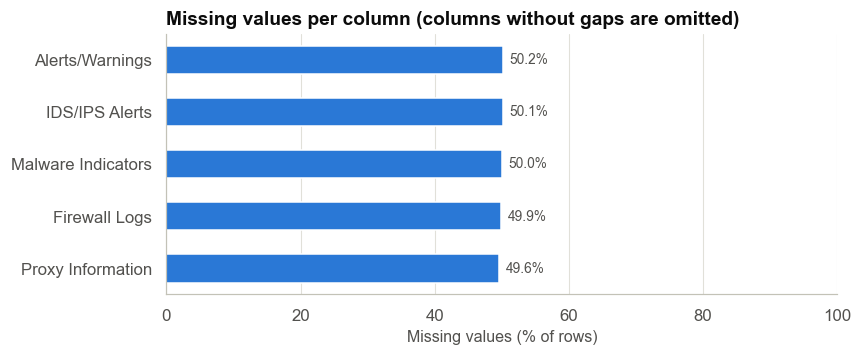

In [5]:
n_dup = df_raw.duplicated().sum()
missing = df_raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = missing / len(df_raw) * 100

print(f'Duplicate rows: {n_dup}')
print(f'Columns with missing values: {len(missing)} of {df_raw.shape[1]}\n')
for col in missing.index:
    values = df_raw[col].dropna()
    print(f'{col:<20} missing = {missing[col]:>6,} ({missing_pct[col]:4.1f}%)  | '
          f'{values.nunique():>6,} distinct non-missing value(s), e.g. {values.iloc[0]!r}')

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(missing.index[::-1], missing_pct.values[::-1], color=ACCENT, height=0.55)
for i, v in enumerate(missing_pct.values[::-1]):
    ax.text(v + 1, i, f'{v:.1f}%', va='center', fontsize=9, color=INK_2)
ax.set_xlim(0, 100)
ax.set_xlabel('Missing values (% of rows)')
ax.set_title('Missing values per column (columns without gaps are omitted)')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Insight.**
* There are **no duplicate rows**.
* Exactly **5 columns** have missing values, each in about 50% of rows (49.6%–50.2%).
* In four of them the non-missing value is a single constant (`IoC Detected`, `Alert Triggered`, `Log Data`, `Alert Data`), and `Proxy Information` holds a proxy IP address. A missing value here does not mean *lost data*. It means *the indicator was not raised / no proxy was used*.

These columns are therefore converted to **binary flags (1 = present, 0 = absent)** instead of being imputed or dropped.

### 1.5 Target variable: class balance

,count,percent
Attack Type,,
DDoS,13428,33.57
Intrusion,13265,33.16
Malware,13307,33.27


Imbalance ratio (largest / smallest class): 1.012
Majority-class share (no-information rate): 33.57%


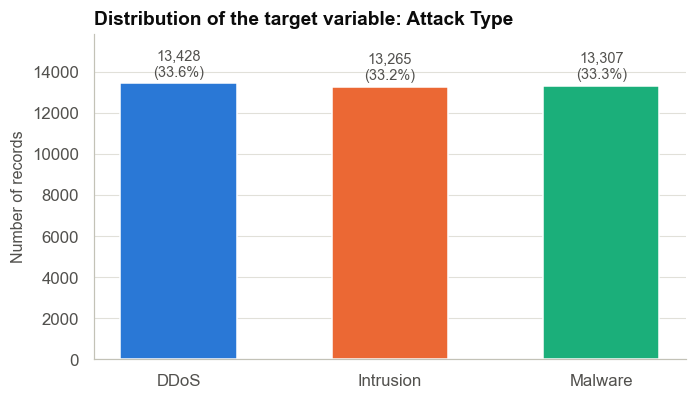

In [6]:
counts = df_raw[TARGET].value_counts().reindex(CLASS_ORDER)
pct = counts / counts.sum() * 100
display(pd.DataFrame({'count': counts, 'percent': pct.round(2)}))
print(f'Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.3f}')
print(f'Majority-class share (no-information rate): {pct.max():.2f}%')

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index], width=0.55)
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, c + 200, f'{c:,}\n({p:.1f}%)', ha='center', va='bottom', fontsize=9.5, color=INK_2)
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel('Number of records')
ax.set_title('Distribution of the target variable: Attack Type')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

**Insight.** The three classes are almost perfectly balanced: DDoS 13,428 (33.57%), Intrusion 13,265 (33.16%) and Malware 13,307 (33.27%), with an imbalance ratio of 1.012. No resampling or class weighting is needed, and accuracy is a meaningful metric. The **no-information rate is 33.57%** (always predicting DDoS), so any useful model must clearly beat about 33.6% accuracy.

### 1.6 Numerical features: distributions and relation to the target

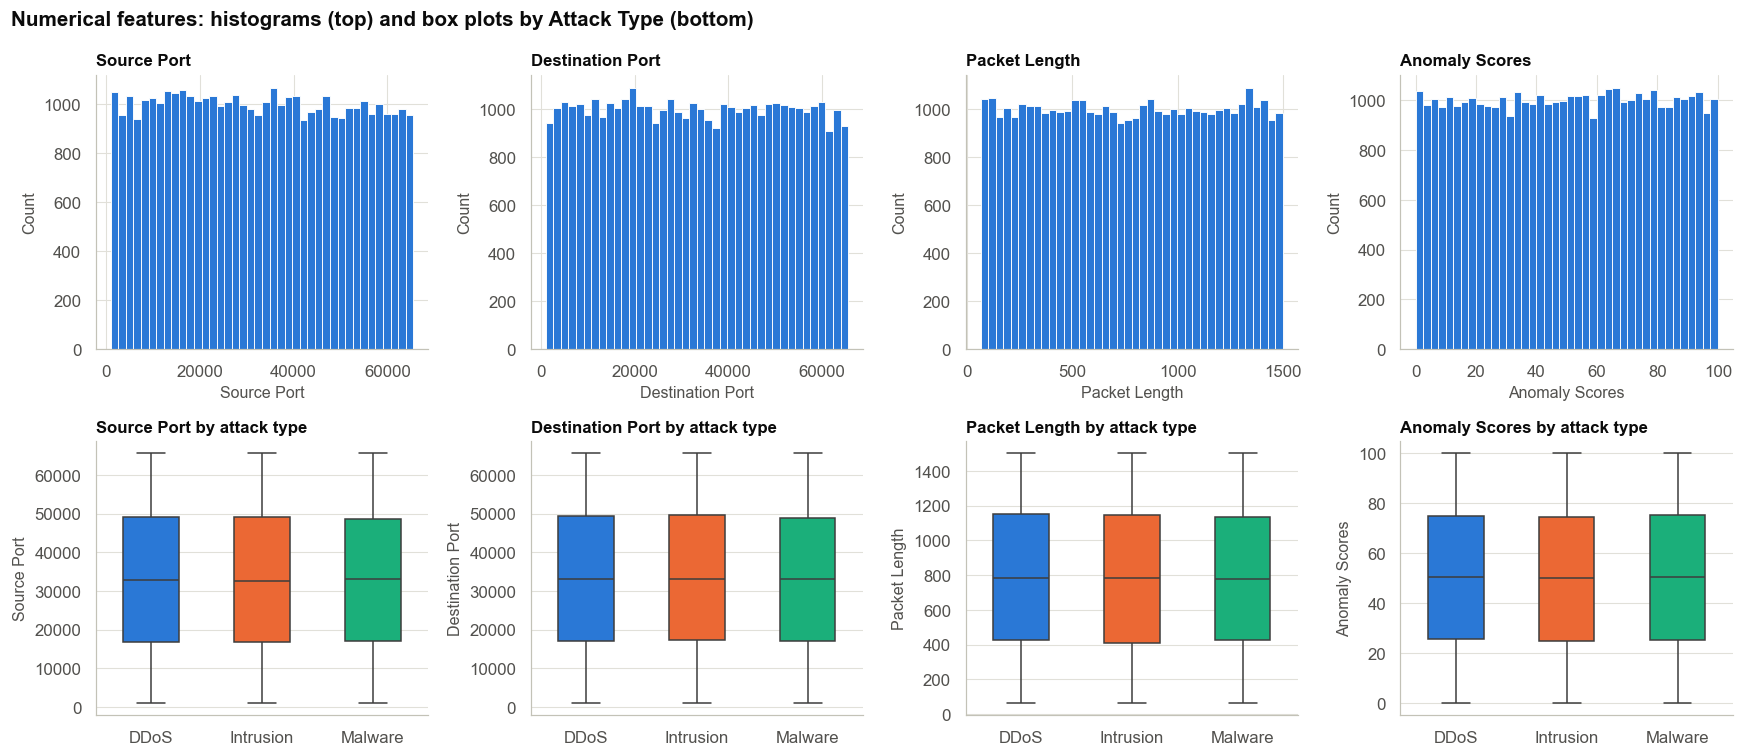

Source Port          Destination Port          Packet Length        Anomaly Scores       
                   mean   median             mean   median          mean median           mean median
Attack Type                                                                                          
DDoS           32944.90  32851.5         33207.36  32986.0        785.35  786.0          50.24  50.42
Intrusion      32987.21  32687.0         33227.41  33035.0        780.92  785.0          49.98  50.18
Malware        32979.25  33044.0         33017.56  32984.0        778.05  777.0          50.13  50.42

In [7]:
NUM_RAW = ['Source Port', 'Destination Port', 'Packet Length', 'Anomaly Scores']

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes[0], NUM_RAW):
    ax.hist(df_raw[col], bins=40, color=ACCENT, edgecolor='white', linewidth=0.6)
    ax.set_title(f'{col}', fontsize=11)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
for ax, col in zip(axes[1], NUM_RAW):
    sns.boxplot(data=df_raw, x=TARGET, y=col, order=CLASS_ORDER, hue=TARGET, hue_order=CLASS_ORDER,
                palette=CLASS_COLORS, width=0.5, linewidth=1, fliersize=2, legend=False, saturation=1, ax=ax)
    ax.set_title(f'{col} by attack type', fontsize=11)
    ax.set_xlabel('')
fig.suptitle('Numerical features: histograms (top) and box plots by Attack Type (bottom)',
             x=0.01, ha='left', fontsize=13.5, fontweight='bold')
plt.tight_layout()
plt.show()

display(df_raw.groupby(TARGET)[NUM_RAW].agg(['mean', 'median']).round(2).reindex(CLASS_ORDER))

**Insight.** All four histograms are flat (approximately uniform), with no skew and no outliers. The box plots are practically identical for the three attack types. Class means differ by at most about 0.26 anomaly-score points (49.98–50.24) and about 7 bytes of packet length (778.05–785.35). **None of the numerical features separates the attack types on its own.**

### 1.7 Categorical features by attack type

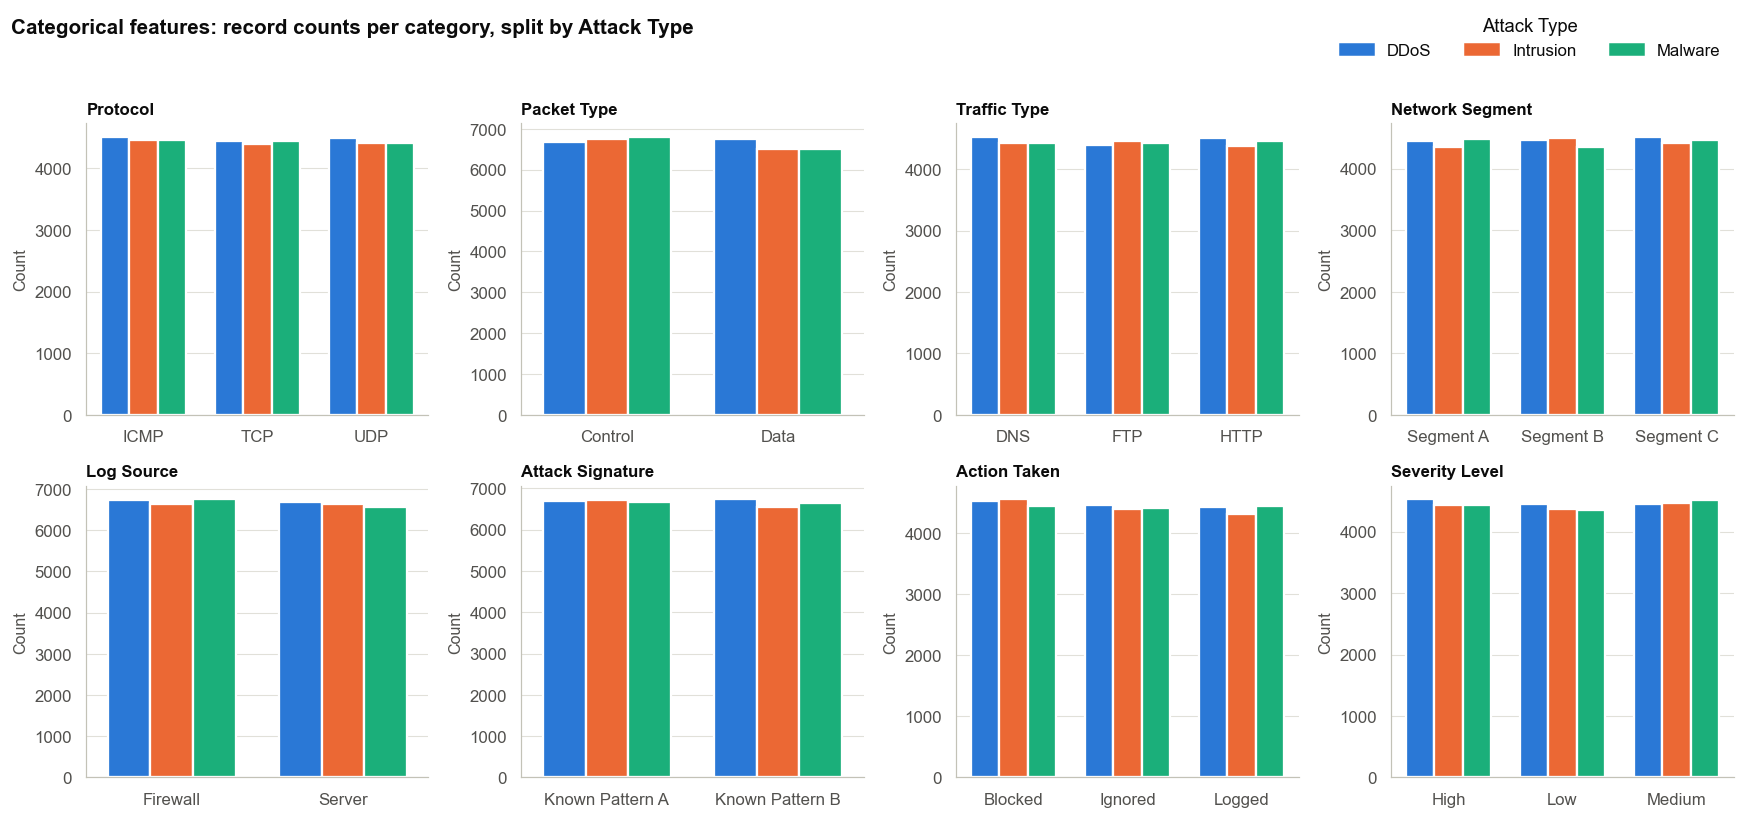

Share of each attack type within every category (%):
  min = 32.67%, max = 34.15%  (a perfectly uninformative feature gives about 33.3%)


In [8]:
CAT_RAW = ['Protocol', 'Packet Type', 'Traffic Type', 'Network Segment',
           'Log Source', 'Attack Signature', 'Action Taken', 'Severity Level']

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, col in zip(axes.ravel(), CAT_RAW):
    order = sorted(df_raw[col].unique())
    sns.countplot(data=df_raw, x=col, hue=TARGET, order=order, hue_order=CLASS_ORDER,
                  palette=CLASS_COLORS, ax=ax, width=0.75, edgecolor='white', linewidth=1.5, saturation=1)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Count')
    ax.get_legend().remove()
    ax.grid(axis='x', visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=CLASS_COLORS[c]) for c in CLASS_ORDER]
fig.legend(handles, CLASS_ORDER, title='Attack Type', loc='upper right', ncol=3, bbox_to_anchor=(0.99, 1.0))
fig.suptitle('Categorical features: record counts per category, split by Attack Type',
             x=0.01, ha='left', fontsize=13.5, fontweight='bold')
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

# Share of each attack type inside every category (rows sum to 100%)
share_tables = []
for col in CAT_RAW:
    t = pd.crosstab(df_raw[col], df_raw[TARGET], normalize='index')[CLASS_ORDER] * 100
    t.index = [f'{col} = {v}' for v in t.index]
    share_tables.append(t)
share = pd.concat(share_tables)
print('Share of each attack type within every category (%):')
print(f'  min = {share.values.min():.2f}%, max = {share.values.max():.2f}%  (a perfectly uninformative feature gives about 33.3%)')

**Insight.** Every category contains the three attack types in almost equal numbers. Within any category, the share of an attack type lies between **32.67% and 34.15%**, while a feature with no association would give 33.3%. This holds even for `Attack Signature`, `Action Taken` and `Severity Level`. These three are still removed in Section 2 because of their *potential* leakage in a real deployment.

#### Security-indicator columns (present vs. missing)

The five sparse columns (`Malware Indicators`, `Alerts/Warnings`, `Firewall Logs`, `IDS/IPS Alerts`, `Proxy Information`) are better described as *indicator present / absent*. The chart shows how often each indicator is present for every attack type.

,Malware Indicators,Alerts/Warnings,Firewall Logs,IDS/IPS Alerts,Proxy Information
Attack Type,,,,,
DDoS,49.55,49.69,49.99,49.87,50.53
Intrusion,50.25,49.19,49.93,49.66,49.73
Malware,50.21,50.61,50.38,50.09,50.85


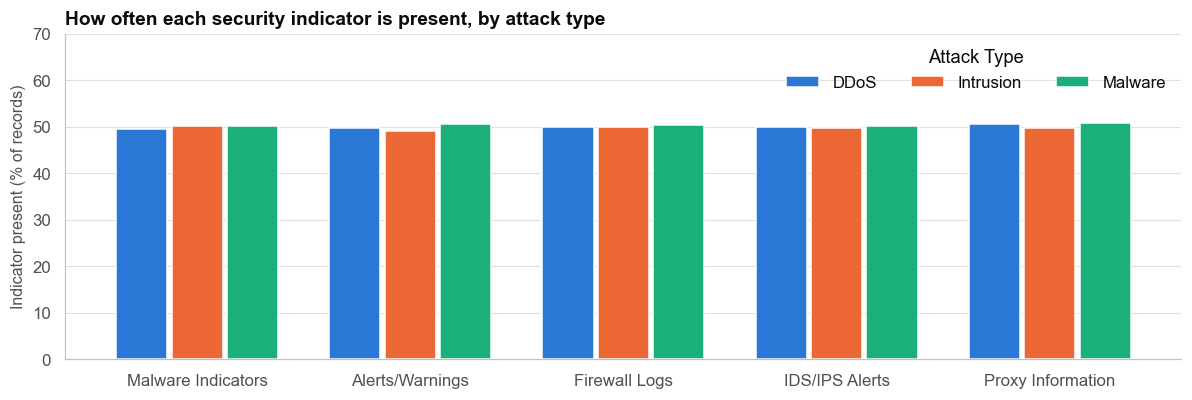

In [9]:
INDICATOR_COLS = ['Malware Indicators', 'Alerts/Warnings', 'Firewall Logs', 'IDS/IPS Alerts', 'Proxy Information']
presence = (df_raw[INDICATOR_COLS].notna()
            .groupby(df_raw[TARGET]).mean().reindex(CLASS_ORDER) * 100)
display(presence.round(2))

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(INDICATOR_COLS))
w = 0.26
for k, cls in enumerate(CLASS_ORDER):
    ax.bar(x + (k - 1) * w, presence.loc[cls], width=w - 0.02, color=CLASS_COLORS[cls], label=cls)
ax.set_xticks(x, INDICATOR_COLS)
ax.set_ylim(0, 70)
ax.set_ylabel('Indicator present (% of records)')
ax.set_title('How often each security indicator is present, by attack type')
ax.legend(title='Attack Type', ncol=3, loc='upper right')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

**Insight.** Each indicator is present in about 50% of records for every attack type (range 49.19%–50.85%). For example, `Malware Indicators` (*IoC Detected*) is present in 50.21% of Malware events but also in 49.55% of DDoS events. The indicators therefore carry **no class-specific information**.

### 1.8 Datetime feature: `Timestamp`

Time range: 2020-01-01 00:43:27  ->  2023-10-11 19:34:23


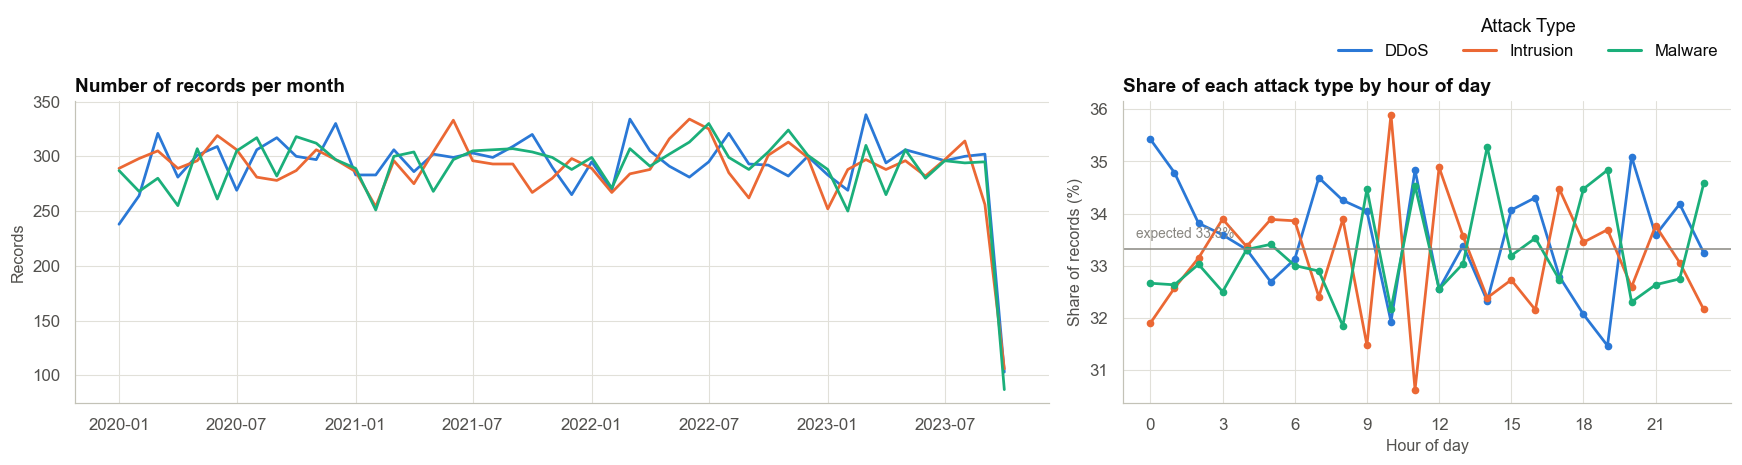

In [10]:
ts = pd.to_datetime(df_raw['Timestamp'])
print(f'Time range: {ts.min()}  ->  {ts.max()}')

monthly = df_raw.groupby([ts.dt.to_period('M'), TARGET]).size().unstack()[CLASS_ORDER]
hourly_share = (pd.crosstab(ts.dt.hour, df_raw[TARGET], normalize='index')[CLASS_ORDER] * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={'width_ratios': [1.6, 1]})
for cls in CLASS_ORDER:
    axes[0].plot(monthly.index.to_timestamp(), monthly[cls], color=CLASS_COLORS[cls], lw=1.8, label=cls)
    axes[1].plot(hourly_share.index, hourly_share[cls], color=CLASS_COLORS[cls], lw=1.8,
                 marker='o', ms=4, label=cls)
axes[0].set_title('Number of records per month')
axes[0].set_ylabel('Records')
axes[1].axhline(100 / 3, color=MUTED, lw=1)
axes[1].text(-0.6, 100 / 3 + 0.15, 'expected 33.3%', color=MUTED, fontsize=9, ha='left', va='bottom')
axes[1].set_title('Share of each attack type by hour of day')
axes[1].set_xlabel('Hour of day')
axes[1].set_ylabel('Share of records (%)')
axes[1].set_xticks(range(0, 24, 3))
handles = [plt.Line2D([0], [0], color=CLASS_COLORS[c], lw=2) for c in CLASS_ORDER]
fig.legend(handles, CLASS_ORDER, title='Attack Type', loc='upper right', ncol=3, bbox_to_anchor=(0.99, 1.02))
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

**Insight.** The records span **2020-01-01 to 2023-10-11** with a roughly constant monthly volume for each class (about 240–340 records per month). The drop at the right edge happens because October 2023 is incomplete. The class shares by hour of day fluctuate randomly between roughly 31% and 36% around 33.3%, with no consistent pattern. **Timing does not reveal the attack type.**

### 1.9 Correlation heatmap

The heatmap uses the numerical features, the time components, the indicator flags (1 = present) and one 0/1 column per attack type (`is_DDoS`, `is_Intrusion`, `is_Malware`). The bottom three rows therefore show the direct linear correlation of every feature with every class.

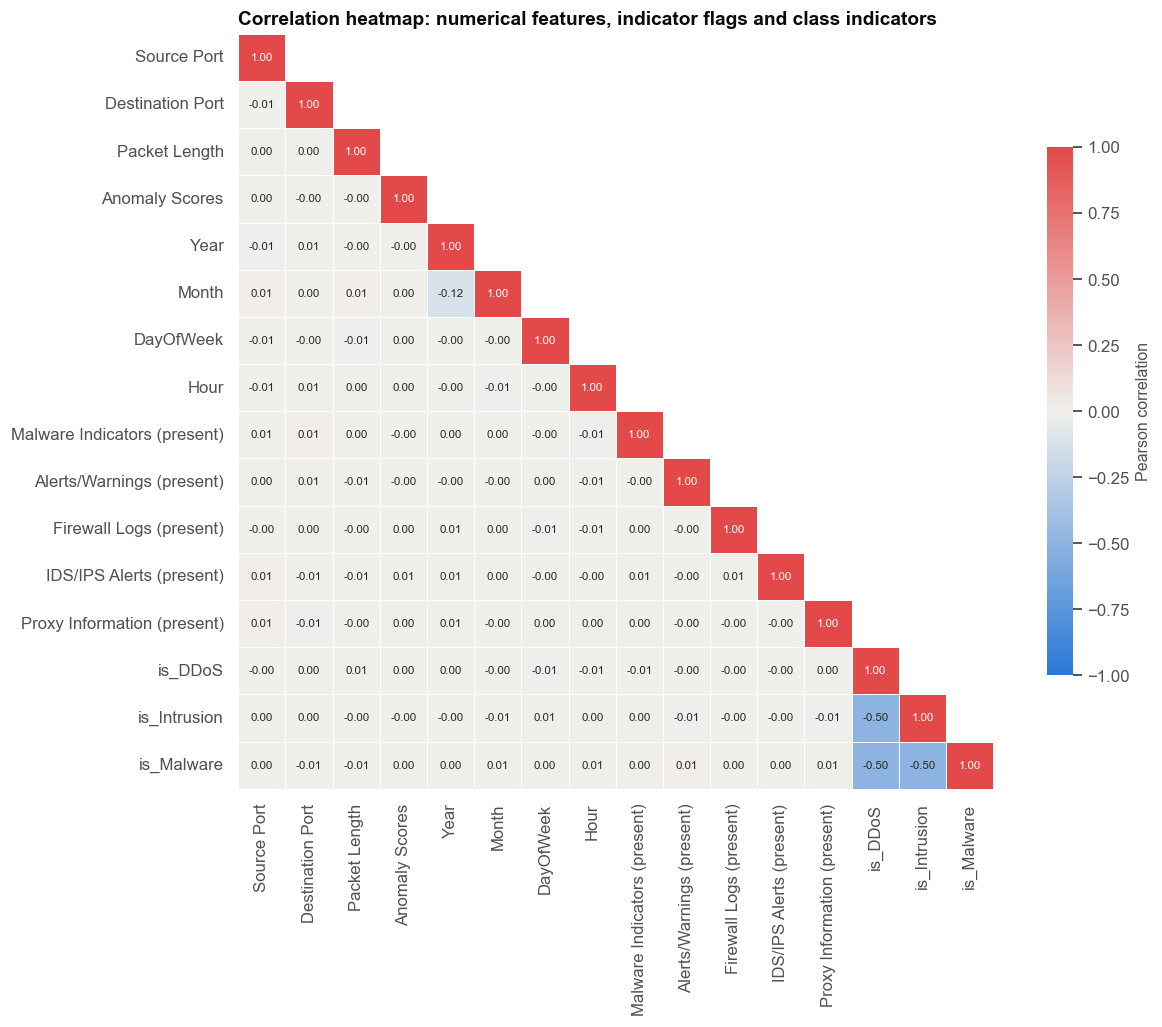

Largest |correlation| between a feature and a class indicator : 0.0110
Largest |correlation| between two different features          : 0.1246


In [11]:
eda_num = pd.DataFrame({
    'Source Port': df_raw['Source Port'],
    'Destination Port': df_raw['Destination Port'],
    'Packet Length': df_raw['Packet Length'],
    'Anomaly Scores': df_raw['Anomaly Scores'],
    'Year': ts.dt.year, 'Month': ts.dt.month, 'DayOfWeek': ts.dt.dayofweek, 'Hour': ts.dt.hour,
})
for col in INDICATOR_COLS:
    eda_num[f'{col} (present)'] = df_raw[col].notna().astype(int)
for cls in CLASS_ORDER:
    eda_num[f'is_{cls}'] = (df_raw[TARGET] == cls).astype(int)

corr = eda_num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr, mask=mask, cmap=DIV_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            annot_kws={'size': 7.5}, linewidths=0.5, linecolor='white', square=True,
            cbar_kws={'shrink': 0.7, 'label': 'Pearson correlation'}, ax=ax)
ax.set_title('Correlation heatmap: numerical features, indicator flags and class indicators')
ax.grid(False)
plt.tight_layout()
plt.show()

class_cols = [f'is_{c}' for c in CLASS_ORDER]
feat_cols = [c for c in corr.columns if c not in class_cols]
feat_target = corr.loc[feat_cols, class_cols]
off_diag = corr.loc[feat_cols, feat_cols].where(~np.eye(len(feat_cols), dtype=bool))
print(f'Largest |correlation| between a feature and a class indicator : {feat_target.abs().max().max():.4f}')
print(f'Largest |correlation| between two different features          : {off_diag.abs().max().max():.4f}')

**Insight.** Almost every cell is about 0. The largest absolute correlation between any feature and any class indicator is only **0.011**. Between two different features the largest is 0.125, which is the expected negative correlation between `Year` and `Month` (the data stops in October 2023). The −0.50 values among the `is_*` columns are structural: the three class indicators are mutually exclusive. There is **no linear signal** linking the features to the attack type, and also no redundant (multicollinear) features.

### 1.10 Strength of association between each feature and the target (Cramér's V)

Pearson correlation only captures *linear* relations. **Cramér's V** (0 = no association, 1 = perfect association) works for any categorical variable. Numerical features are first binned into deciles. A common rule of thumb treats V < 0.10 as negligible.

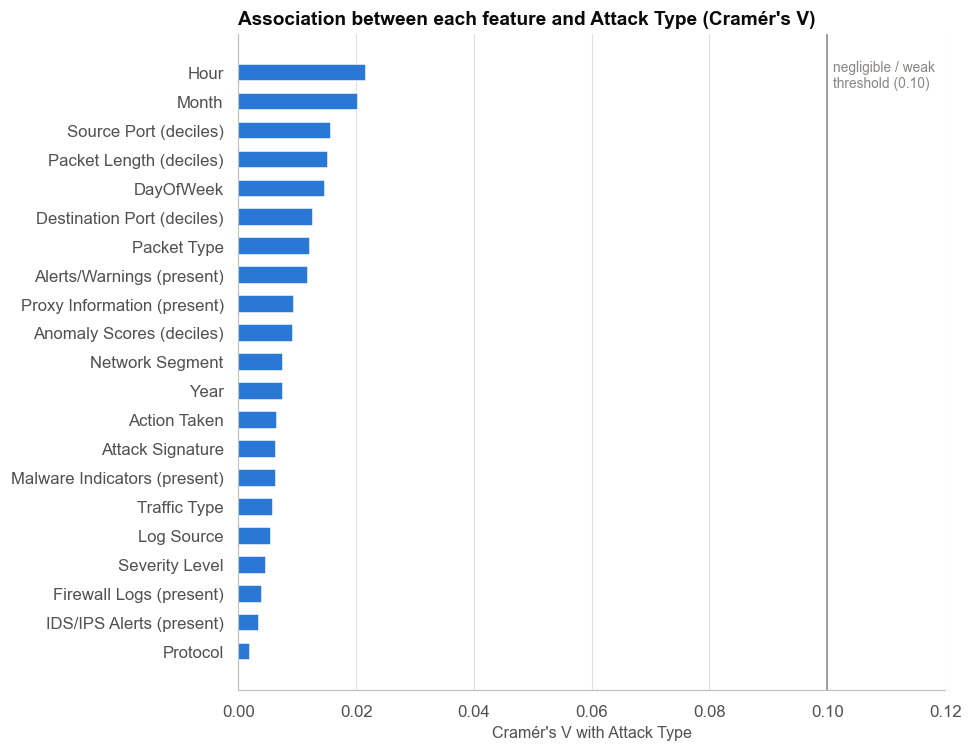

Hour                          0.0218
Month                         0.0203
Source Port (deciles)         0.0158
Packet Length (deciles)       0.0153
DayOfWeek                     0.0148
Destination Port (deciles)    0.0128


In [12]:
def cramers_v(x, y):
    # Cramér's V computed from the chi-square statistic of the contingency table.
    table = pd.crosstab(x, y).to_numpy().astype(float)
    n = table.sum()
    expected = table.sum(axis=1, keepdims=True) @ table.sum(axis=0, keepdims=True) / n
    chi2 = ((table - expected) ** 2 / expected).sum()
    return math.sqrt(chi2 / (n * (min(table.shape) - 1)))

assoc_inputs = {col: df_raw[col] for col in CAT_RAW}
assoc_inputs.update({f'{col} (present)': df_raw[col].notna() for col in INDICATOR_COLS})
assoc_inputs.update({f'{col} (deciles)': pd.qcut(df_raw[col], 10, duplicates='drop') for col in NUM_RAW})
assoc_inputs.update({'Hour': ts.dt.hour, 'DayOfWeek': ts.dt.dayofweek, 'Month': ts.dt.month, 'Year': ts.dt.year})

cramer = pd.Series({name: cramers_v(s, df_raw[TARGET]) for name, s in assoc_inputs.items()}).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(cramer.index, cramer.values, color=ACCENT, height=0.6)
ax.axvline(0.10, color=MUTED, lw=1)
ax.text(0.101, len(cramer) - 0.6, 'negligible / weak\nthreshold (0.10)', color=MUTED, fontsize=9, va='top')
ax.set_xlim(0, 0.12)
ax.set_xlabel("Cramér's V with Attack Type")
ax.set_title("Association between each feature and Attack Type (Cramér's V)")
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()
print(cramer.sort_values(ascending=False).round(4).head(6).to_string())

**Insight.** All Cramér's V values are tiny (the largest is **0.022** for `Hour`, then 0.020 for `Month`), far below the 0.10 threshold for even a *weak* association. Features with many categories (24 hours, 12 months, 10 deciles) score slightly higher simply because Cramér's V has a small positive bias for finite samples. This reflects random variation, not a real effect.

### EDA summary

1. **Clean structure.** There are 40,000 rows, no duplicates and a balanced target (≈ 33% per class). The only missing values are "indicator not present" markers, not lost data.
2. **Many unusable columns.** IP addresses, payload text, names, user agents and locations are (near-)unique identifiers.
3. **No visible relationship between any feature and `Attack Type`.** Distributions, category shares, indicator rates, timing, correlations and Cramér's V all show the same picture: every attack type looks statistically the same. This strongly suggests the dataset is synthetic, with labels generated independently of the features. **We therefore expect any classifier, including a Decision Tree, to perform close to chance level (≈ 33%).** The following sections test this expectation rigorously.

## 2. Data Preprocessing

### 2.1 Target, feature selection and removed columns

**Target:** `Attack Type` (3 classes).

Every column is reviewed below. Columns are removed for one of three reasons:

* **Identifiers or free text.** These values are (almost) unique per row, so a tree would only memorise them and they cannot generalise. This covers IP addresses, payload text, user names and user-agent strings.
* **Potential target leakage.** Some fields are produced *after* the attack has been analysed and identified: the matched signature, the response action and the severity assigned by an analyst. At prediction time they would not be available yet, or they would already encode the answer. A model trained on them would therefore look better than it really is.
* **Non-stationary value.** `Year` would not generalise to future data (2024 and later), so only cyclic time components are kept.

In [13]:
column_decisions = pd.DataFrame([
    ('Timestamp',              'transform', 'Extract Month, DayOfWeek, Hour (cyclic patterns); Year is not used (non-stationary)'),
    ('Source IP Address',      'drop',      'Identifier: unique for every row (40,000 values)'),
    ('Destination IP Address', 'drop',      'Identifier: unique for every row (40,000 values)'),
    ('Source Port',            'keep',      'Numerical network attribute'),
    ('Destination Port',       'keep',      'Numerical network attribute'),
    ('Protocol',               'keep',      'Categorical (3 values), one-hot encoded'),
    ('Packet Length',          'keep',      'Numerical network attribute'),
    ('Packet Type',            'keep',      'Categorical (2 values), one-hot encoded'),
    ('Traffic Type',           'keep',      'Categorical (3 values), one-hot encoded'),
    ('Payload Data',           'drop',      'Free text that is unique for every row (random placeholder text)'),
    ('Malware Indicators',     'transform', 'Single value or missing, so converted to a 0/1 flag (IoC detected)'),
    ('Anomaly Scores',         'keep',      'Numerical score produced by the detection system'),
    ('Alerts/Warnings',        'transform', 'Single value or missing, so converted to a 0/1 flag'),
    ('Attack Type',            'target',    'Variable to predict'),
    ('Attack Signature',       'drop',      'Potential leakage: result of signature matching that identifies the attack'),
    ('Action Taken',           'drop',      'Potential leakage: response decided after the attack type is known'),
    ('Severity Level',         'drop',      'Potential leakage: severity assigned during incident analysis'),
    ('User Information',       'drop',      'Personal names (PII), high cardinality, not a behavioural signal'),
    ('Device Information',     'drop',      'User-agent strings, about 32k unique values'),
    ('Network Segment',        'keep',      'Categorical (3 values), one-hot encoded'),
    ('Geo-location Data',      'drop',      'City/state text with about 8.7k unique values'),
    ('Proxy Information',      'transform', 'Proxy IP is an identifier, so only a 0/1 flag "uses proxy" is kept'),
    ('Firewall Logs',          'transform', 'Single value or missing, so converted to a 0/1 flag'),
    ('IDS/IPS Alerts',         'transform', 'Single value or missing, so converted to a 0/1 flag'),
    ('Log Source',             'keep',      'Categorical (2 values), one-hot encoded'),
], columns=['column', 'decision', 'reason'])
column_decisions['n_unique'] = column_decisions['column'].map(df_raw.nunique())
print(column_decisions['decision'].value_counts().to_string())
column_decisions

decision
drop         9
keep         9
transform    6
target       1


,column,decision,reason,n_unique
0,Timestamp,transform,"Extract Month, DayOfWeek, Hour (cyclic pattern...",39997
1,Source IP Address,drop,"Identifier: unique for every row (40,000 values)",40000
2,Destination IP Address,drop,"Identifier: unique for every row (40,000 values)",40000
3,Source Port,keep,Numerical network attribute,29761
4,Destination Port,keep,Numerical network attribute,29895
5,Protocol,keep,"Categorical (3 values), one-hot encoded",3
6,Packet Length,keep,Numerical network attribute,1437
7,Packet Type,keep,"Categorical (2 values), one-hot encoded",2
8,Traffic Type,keep,"Categorical (3 values), one-hot encoded",3
9,Payload Data,drop,Free text that is unique for every row (random...,40000


### 2.2 Duplicates, missing target values and feature engineering

* **Duplicates.** None were found, but `drop_duplicates()` is kept in the code to make the pipeline robust.
* **Missing values.** In the five indicator columns a missing value means *the indicator was not raised*. They are therefore converted into binary flags instead of being imputed. `SimpleImputer` steps are still placed inside the model pipeline as a safety net for unseen data.
* **Datetime.** `Timestamp` is converted to `Month`, `DayOfWeek` and `Hour`.

These steps are **stateless row-wise transformations**: they do not learn any statistic from the data, so applying them before the train/test split cannot leak information. Every step that *learns* from data (imputation values, one-hot categories) is placed inside a scikit-learn `Pipeline` and fitted on the training folds only.

In [14]:
INDICATOR_FLAGS = {
    'Malware Indicators': 'Has Malware Indicator',
    'Alerts/Warnings':    'Has Alert',
    'Firewall Logs':      'Has Firewall Log',
    'IDS/IPS Alerts':     'Has IDS/IPS Alert',
    'Proxy Information':  'Uses Proxy',
}
NUMERIC_FEATURES = ['Source Port', 'Destination Port', 'Packet Length', 'Anomaly Scores',
                    'Month', 'DayOfWeek', 'Hour']
BINARY_FEATURES = list(INDICATOR_FLAGS.values())
CATEGORICAL_FEATURES = ['Protocol', 'Packet Type', 'Traffic Type', 'Network Segment', 'Log Source']
FEATURES = NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES


def engineer_features(data):
    # Stateless, row-wise feature engineering (safe to apply before the split).
    out = data.copy()
    timestamp = pd.to_datetime(out['Timestamp'], errors='coerce')
    out['Month'] = timestamp.dt.month
    out['DayOfWeek'] = timestamp.dt.dayofweek
    out['Hour'] = timestamp.dt.hour
    for source_col, flag_col in INDICATOR_FLAGS.items():
        out[flag_col] = out[source_col].notna().astype(int)
    return out


df = df_raw.drop_duplicates().dropna(subset=[TARGET]).reset_index(drop=True)
df_model = engineer_features(df)

X = df_model[FEATURES]
y = df_model[TARGET]
print(f'Rows after cleaning: {len(df):,} (removed {len(df_raw) - len(df)} duplicate / unlabeled rows)')
print(f'Input features: {len(FEATURES)}  ->  {len(NUMERIC_FEATURES)} numerical, '
      f'{len(BINARY_FEATURES)} binary flags, {len(CATEGORICAL_FEATURES)} categorical')
X.head()

Rows after cleaning: 40,000 (removed 0 duplicate / unlabeled rows)
Input features: 17  ->  7 numerical, 5 binary flags, 5 categorical


,Source Port,Destination Port,Packet Length,Anomaly Scores,Month,DayOfWeek,Hour,Has Malware Indicator,Has Alert,Has Firewall Log,Has IDS/IPS Alert,Uses Proxy,Protocol,Packet Type,Traffic Type,Network Segment,Log Source
0,31225,17616,503,28.67,5,1,6,1,0,1,0,1,ICMP,Data,HTTP,Segment A,Server
1,17245,48166,1174,51.50,8,2,7,1,0,1,0,0,ICMP,Data,HTTP,Segment B,Firewall
2,16811,53600,306,87.42,11,6,8,1,1,1,1,1,UDP,Control,HTTP,Segment C,Firewall
3,20018,32534,385,15.79,7,6,10,0,1,0,1,0,UDP,Data,HTTP,Segment B,Firewall
4,6131,26646,1462,0.52,7,6,13,0,1,0,1,1,TCP,Data,DNS,Segment C,Firewall


### 2.3 Train / test split (80% / 20%, stratified)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

split_table = pd.DataFrame({
    'train (%)': y_train.value_counts(normalize=True) * 100,
    'test (%)': y_test.value_counts(normalize=True) * 100,
}).reindex(CLASS_ORDER).round(2)
print(f'Training set: {X_train.shape[0]:,} rows | Test set: {X_test.shape[0]:,} rows')
split_table

Training set: 32,000 rows | Test set: 8,000 rows


,train (%),test (%)
Attack Type,,
DDoS,33.57,33.58
Intrusion,33.16,33.16
Malware,33.27,33.26


### 2.4 Preprocessing pipeline

A `ColumnTransformer` handles each feature group:

| Group | Transformation | Why |
|---|---|---|
| Numerical | `SimpleImputer(median)` | Decision trees split on thresholds, so **no scaling is needed** |
| Binary flags | passthrough | Already 0/1 |
| Categorical | `SimpleImputer(most_frequent)` then `OneHotEncoder(handle_unknown='ignore')` | Trees need numeric inputs; one-hot avoids imposing a fake order |

The preprocessor and the classifier are wrapped in a single `Pipeline`, so during cross-validation the preprocessing is re-fitted inside every training fold. This prevents data leakage.

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), NUMERIC_FEATURES),
        ('bin', 'passthrough', BINARY_FEATURES),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),
         CATEGORICAL_FEATURES),
    ],
    verbose_feature_names_out=False,
)


def make_tree_pipeline(**tree_params):
    # Preprocessing + Decision Tree in one leakage-safe pipeline.
    return Pipeline([
        ('preprocess', clone(preprocessor)),
        ('tree', DecisionTreeClassifier(random_state=RANDOM_STATE, **tree_params)),
    ])


encoded_names = clone(preprocessor).fit(X_train).get_feature_names_out()
print(f'Number of model inputs after encoding: {len(encoded_names)}')
print(list(encoded_names))
make_tree_pipeline()

Number of model inputs after encoding: 25


['Source Port', 'Destination Port', 'Packet Length', 'Anomaly Scores', 'Month', 'DayOfWeek', 'Hour', 'Has Malware Indicator', 'Has Alert', 'Has Firewall Log', 'Has IDS/IPS Alert', 'Uses Proxy', 'Protocol_ICMP', 'Protocol_TCP', 'Protocol_UDP', 'Packet Type_Control', 'Packet Type_Data', 'Traffic Type_DNS', 'Traffic Type_FTP', 'Traffic Type_HTTP', 'Network Segment_Segment A', 'Network Segment_Segment B', 'Network Segment_Segment C', 'Log Source_Firewall', 'Log Source_Server']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('tree', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers 

## 3. Decision Tree Classification

### 3.1 Reference model and baseline Decision Tree

* **Reference model.** `DummyClassifier(strategy='stratified')` predicts random labels that follow the training class proportions. It shows the score of *pure guessing*.
* **Baseline Decision Tree.** `DecisionTreeClassifier` with default settings: the tree grows until all leaves are pure, with no depth limit.

In [17]:
dummy = Pipeline([('preprocess', clone(preprocessor)),
                  ('model', DummyClassifier(strategy='stratified', random_state=RANDOM_STATE))])
dummy.fit(X_train, y_train)

baseline = make_tree_pipeline()
t0 = time.perf_counter()
baseline.fit(X_train, y_train)
baseline_time = time.perf_counter() - t0

base_tree = baseline.named_steps['tree']
print(f'Baseline training time : {baseline_time:.2f} s')
print(f'Tree depth             : {base_tree.get_depth()}')
print(f'Number of leaves       : {base_tree.get_n_leaves():,}')
print(f'Training accuracy      : {accuracy_score(y_train, baseline.predict(X_train)):.4f}')
print(f'Test accuracy          : {accuracy_score(y_test, baseline.predict(X_test)):.4f}')
print(f'Dummy test accuracy    : {accuracy_score(y_test, dummy.predict(X_test)):.4f}')

Baseline training time : 1.43 s
Tree depth             : 53
Number of leaves       : 11,178
Training accuracy      : 1.0000
Test accuracy          : 0.3324


Dummy test accuracy    : 0.3390


**Insight.** The fully grown baseline tree reaches depth **53** with **11,178 leaves**. That is roughly one leaf for every 3 training records. It memorises the training data (**train accuracy = 100%**), but its test accuracy is only **33.24%**. This is no better than the random-guess dummy (33.90%) and is a textbook case of **overfitting**: the tree learned noise, not patterns.

### 3.2 Hyperparameter tuning with cross-validation

`GridSearchCV` with **5-fold stratified cross-validation** on the training set only, using **macro F1** as the selection metric because it treats every class equally. Tuned hyperparameters:

* `criterion`: impurity measure (`gini`, `entropy`)
* `max_depth`: maximum depth of the tree
* `min_samples_split`: minimum samples needed to split a node
* `min_samples_leaf`: minimum samples required in every leaf

The grid is kept small because every fit takes a few seconds on this dataset. The test set is **not** used here.

In [18]:
param_grid = {
    'tree__criterion': ['gini', 'entropy'],
    'tree__max_depth': [3, 5, 8, None],
    'tree__min_samples_split': [2, 50],
    'tree__min_samples_leaf': [1, 20],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(make_tree_pipeline(), param_grid, scoring='f1_macro', cv=cv,
                    n_jobs=-1, return_train_score=True, refit=True)

t0 = time.perf_counter()
grid.fit(X_train, y_train)
n_candidates = len(grid.cv_results_['params'])
print(f'Grid search: {n_candidates} candidates x 5 folds = {n_candidates * 5} fits '
      f'in {time.perf_counter() - t0:.1f} s')
print(f'Best parameters  : {grid.best_params_}')
print(f'Best CV macro F1 : {grid.best_score_:.4f}')

cv_results = pd.DataFrame(grid.cv_results_)
cv_table = (cv_results
            .assign(max_depth=cv_results['param_tree__max_depth'].astype(str).replace('None', 'None (unlimited)'))
            [['rank_test_score', 'param_tree__criterion', 'max_depth', 'param_tree__min_samples_split',
              'param_tree__min_samples_leaf', 'mean_train_score', 'mean_test_score', 'std_test_score']]
            .rename(columns={'param_tree__criterion': 'criterion',
                             'param_tree__min_samples_split': 'min_samples_split',
                             'param_tree__min_samples_leaf': 'min_samples_leaf',
                             'mean_train_score': 'train F1 (macro)',
                             'mean_test_score': 'CV F1 (macro)',
                             'std_test_score': 'CV std'})
            .sort_values('rank_test_score'))
cv_table.head(10).round(4)

Grid search: 32 candidates x 5 folds = 160 fits in 61.5 s
Best parameters  : {'tree__criterion': 'entropy', 'tree__max_depth': None, 'tree__min_samples_leaf': 1, 'tree__min_samples_split': 50}
Best CV macro F1 : 0.3338


,rank_test_score,criterion,max_depth,min_samples_split,min_samples_leaf,train F1 (macro),CV F1 (macro),CV std
29,1,entropy,None (unlimited),50,1,0.5497,0.3338,0.0037
13,2,gini,None (unlimited),50,1,0.5615,0.3338,0.0046
31,3,entropy,None (unlimited),50,20,0.5159,0.3329,0.0065
28,4,entropy,None (unlimited),2,1,1.0000,0.3326,0.0038
15,5,gini,None (unlimited),50,20,0.5286,0.3323,0.0049
12,6,gini,None (unlimited),2,1,1.0000,0.3317,0.0085
30,7,entropy,None (unlimited),2,20,0.5288,0.3314,0.0064
14,8,gini,None (unlimited),2,20,0.5411,0.3305,0.0068
27,9,entropy,8,50,20,0.3627,0.3241,0.0108
26,10,entropy,8,2,20,0.3630,0.3238,0.0110


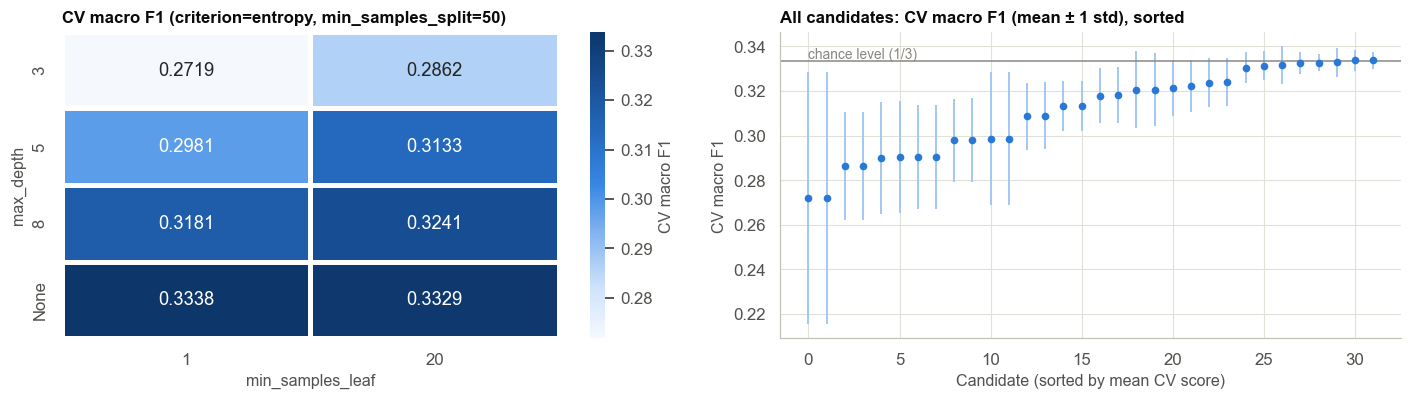

In [19]:
# Mean CV macro-F1 for every max_depth x min_samples_leaf combination
# (criterion and min_samples_split fixed at their best values)
best = grid.best_params_
sub = cv_results[(cv_results['param_tree__criterion'] == best['tree__criterion']) &
                 (cv_results['param_tree__min_samples_split'] == best['tree__min_samples_split'])].copy()
sub['max_depth'] = sub['param_tree__max_depth'].astype(str)
heat = sub.pivot_table(index='max_depth', columns='param_tree__min_samples_leaf',
                       values='mean_test_score').reindex(['3', '5', '8', 'None'])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.heatmap(heat, annot=True, fmt='.4f', cmap=SEQ_CMAP, cbar_kws={'label': 'CV macro F1'},
            linewidths=2, linecolor='white', ax=axes[0])
axes[0].set_title(f"CV macro F1 (criterion={best['tree__criterion']}, "
                  f"min_samples_split={best['tree__min_samples_split']})", fontsize=11)
axes[0].set_xlabel('min_samples_leaf')
axes[0].set_ylabel('max_depth')

ranked = cv_results.sort_values('mean_test_score')
axes[1].errorbar(np.arange(len(ranked)), ranked['mean_test_score'], yerr=ranked['std_test_score'],
                 fmt='o', ms=4, color=ACCENT, ecolor='#9ec5f4', elinewidth=1.2, capsize=0)
axes[1].axhline(1 / 3, color=MUTED, lw=1)
axes[1].text(0, 1 / 3 + 0.001, 'chance level (1/3)', color=MUTED, fontsize=9)
axes[1].set_title('All candidates: CV macro F1 (mean ± 1 std), sorted', fontsize=11)
axes[1].set_xlabel('Candidate (sorted by mean CV score)')
axes[1].set_ylabel('CV macro F1')
plt.tight_layout()
plt.show()

**Insight.**
* The best configuration is `criterion='entropy'`, `max_depth=None`, `min_samples_split=50`, `min_samples_leaf=1`, with a **CV macro F1 of 0.3338 ± 0.0037**.
* The top 8 candidates all score between 0.3305 and 0.3338. These differences are far smaller than their fold-to-fold standard deviations (≈ 0.004–0.009), so the "best" model wins **by chance** rather than by a real margin.
* Shallow trees score *lower* in macro F1 (0.272 at depth 3). A shallow tree on data without signal predicts mostly one or two classes, so the third class gets an F1 near 0, which pulls down the macro average. Their accuracy stays near 33%, as the validation curve in Section 4.5 shows.
* Every point in the right-hand chart lies at or below the chance line (1/3).

### 3.3 Baseline vs. optimised model

In [20]:
tuned = grid.best_estimator_
tuned_tree = tuned.named_steps['tree']

# The baseline configuration (gini, unlimited depth, split=2, leaf=1) is part of the grid,
# so its cross-validated score can be read directly from the search results.
is_base = ((cv_results['param_tree__criterion'] == 'gini') &
           (cv_results['param_tree__max_depth'].isna()) &
           (cv_results['param_tree__min_samples_split'] == 2) &
           (cv_results['param_tree__min_samples_leaf'] == 1))
base_cv = cv_results.loc[is_base, 'mean_test_score'].iloc[0]

structure = pd.DataFrame({
    'Baseline DT': [base_tree.get_depth(), base_tree.get_n_leaves(),
                    f1_score(y_train, baseline.predict(X_train), average='macro'), base_cv,
                    f1_score(y_test, baseline.predict(X_test), average='macro')],
    'Tuned DT': [tuned_tree.get_depth(), tuned_tree.get_n_leaves(),
                 f1_score(y_train, tuned.predict(X_train), average='macro'), grid.best_score_,
                 f1_score(y_test, tuned.predict(X_test), average='macro')],
}, index=['Tree depth', 'Number of leaves', 'Train macro F1', 'CV macro F1 (5-fold)', 'Test macro F1'])
structure.round(4)

,Baseline DT,Tuned DT
Tree depth,53.0000,43.0000
Number of leaves,11178.0000,1532.0000
Train macro F1,1.0000,0.5525
CV macro F1 (5-fold),0.3317,0.3338
Test macro F1,0.3324,0.3295


**Insight.** Tuning made the tree far **simpler**: depth went from 53 to 43 and leaves from 11,178 to 1,532 (−86%). Train macro F1 fell from 1.000 to 0.553, so the regularisation (`min_samples_split=50`) reduced memorisation. Predictive power **did not improve**, however. The CV macro F1 is 0.3338 vs 0.3317, and the test macro F1 is 0.3295 vs 0.3324. Both differences are well within random variation.

### 3.4 Visualising the learned Decision Tree

Only the top levels are drawn so the tree stays readable. The node colour shows the majority class, and a stronger colour means a purer node (white means the classes are mixed). `value` gives the class proportions in the order [DDoS, Intrusion, Malware].

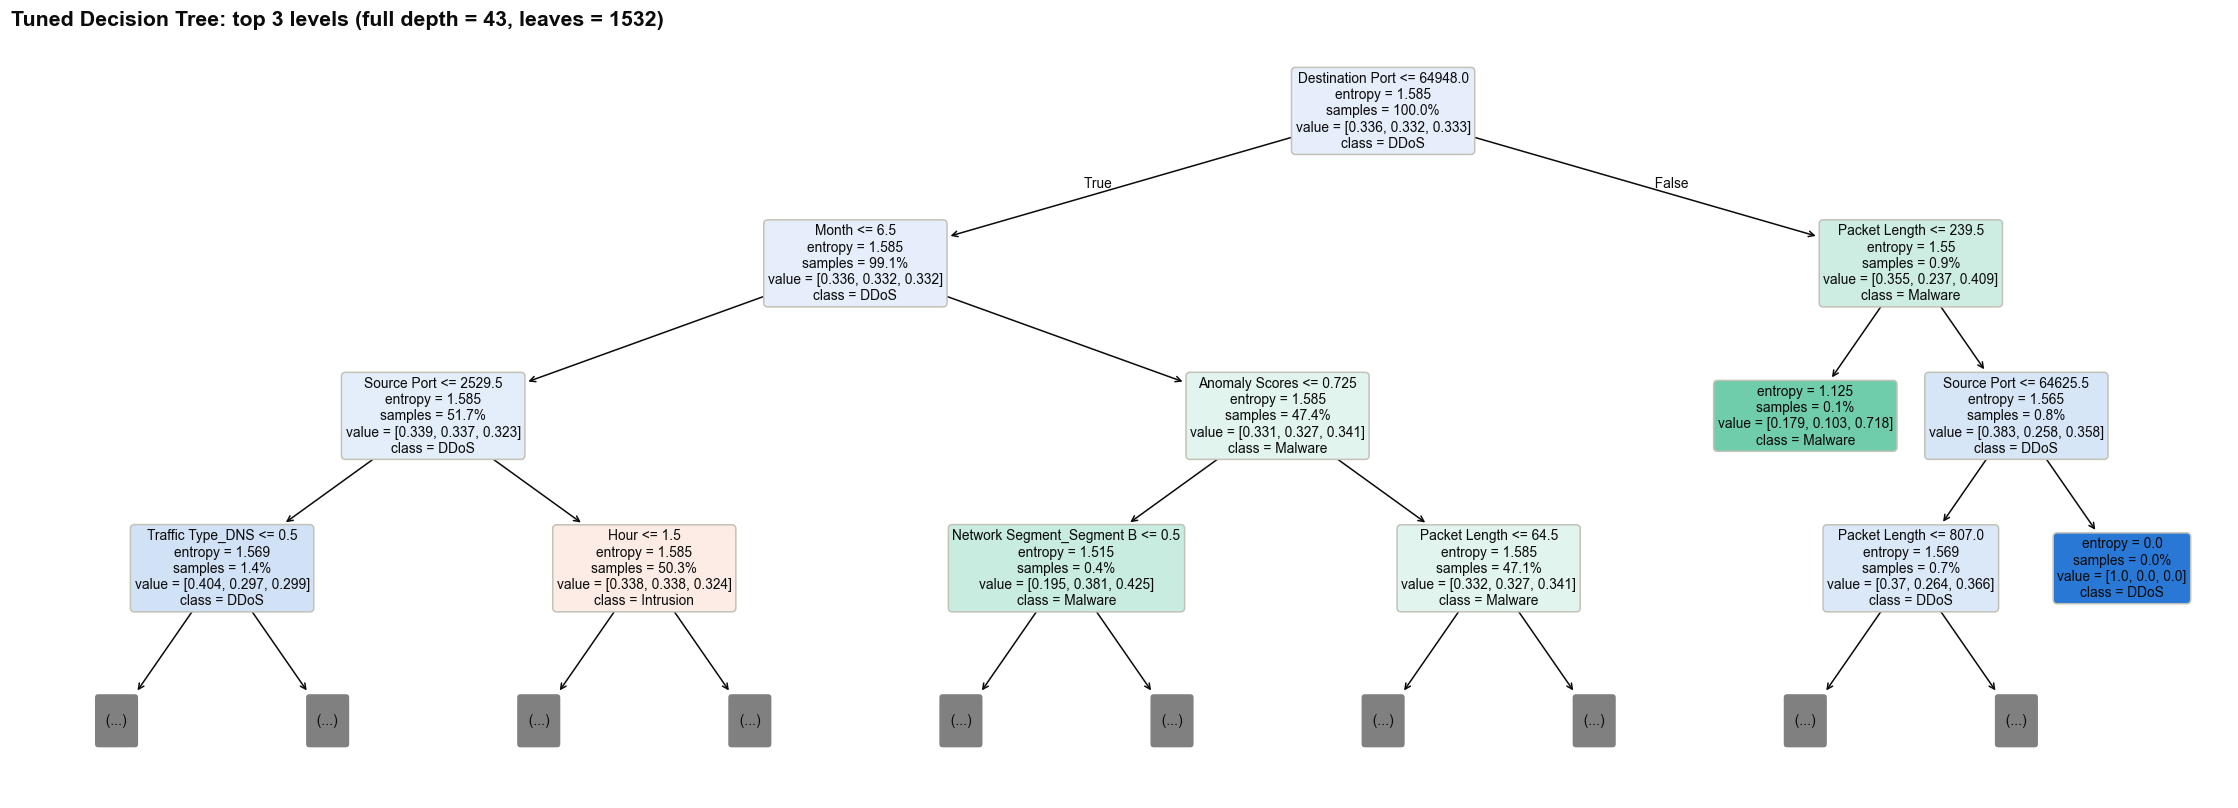

In [21]:
def blend_with_white(hex_color, strength):
    rgb = np.array(to_rgb(hex_color))
    return tuple(1 - strength * (1 - rgb))

feature_names = tuned.named_steps['preprocess'].get_feature_names_out()
class_names = list(tuned_tree.classes_)
PLOT_DEPTH = min(3, tuned_tree.get_depth())

fig, ax = plt.subplots(figsize=(26, 9))
artists = plot_tree(tuned_tree, max_depth=PLOT_DEPTH, feature_names=feature_names, class_names=class_names,
                    filled=True, impurity=True, proportion=True, rounded=True, precision=3,
                    fontsize=9, ax=ax)
for art in artists:                      # recolour nodes with the notebook's class colours
    text = art.get_text()
    cls_match = re.search(r'class = (\S+)', text)
    val_match = re.search(r'value = \[([^\]]+)\]', text)
    if cls_match and val_match and art.get_bbox_patch() is not None:
        props = np.array([float(v) for v in val_match.group(1).replace('\n', ' ').split(',')])
        purity = (props.max() - 1 / 3) / (2 / 3)          # 0 = perfectly mixed, 1 = pure
        art.get_bbox_patch().set_facecolor(blend_with_white(CLASS_COLORS[cls_match.group(1)],
                                                            0.12 + 0.88 * purity))
        art.get_bbox_patch().set_edgecolor('#c3c2b7')
ax.set_title(f'Tuned Decision Tree: top {PLOT_DEPTH} levels '
             f'(full depth = {tuned_tree.get_depth()}, leaves = {tuned_tree.get_n_leaves()})', fontsize=14)
plt.show()

**Insight.** The root split is `Destination Port <= 64948`. It sends 99.1% of the samples left, and the class proportions there are still [0.336, 0.332, 0.332], essentially unchanged from the root. The splits isolate tiny corners of the feature space (e.g. 0.1%–1.4% of the samples) where a few training records happen to share a label. All large nodes stay almost white (entropy ≈ 1.585 = log₂3, the maximum for 3 classes), which shows that **no split meaningfully purifies the classes**.

### 3.5 Feature importance

* **Impurity-based importance (MDI).** This is how much each encoded feature reduces impurity inside the tree. It is computed on the training data and tends to favour continuous, high-cardinality features.
* **Permutation importance on the test set.** This is the drop in test accuracy when one original feature is randomly shuffled. It is more reliable: values ≈ 0 or below 0 mean the feature does not really help prediction.

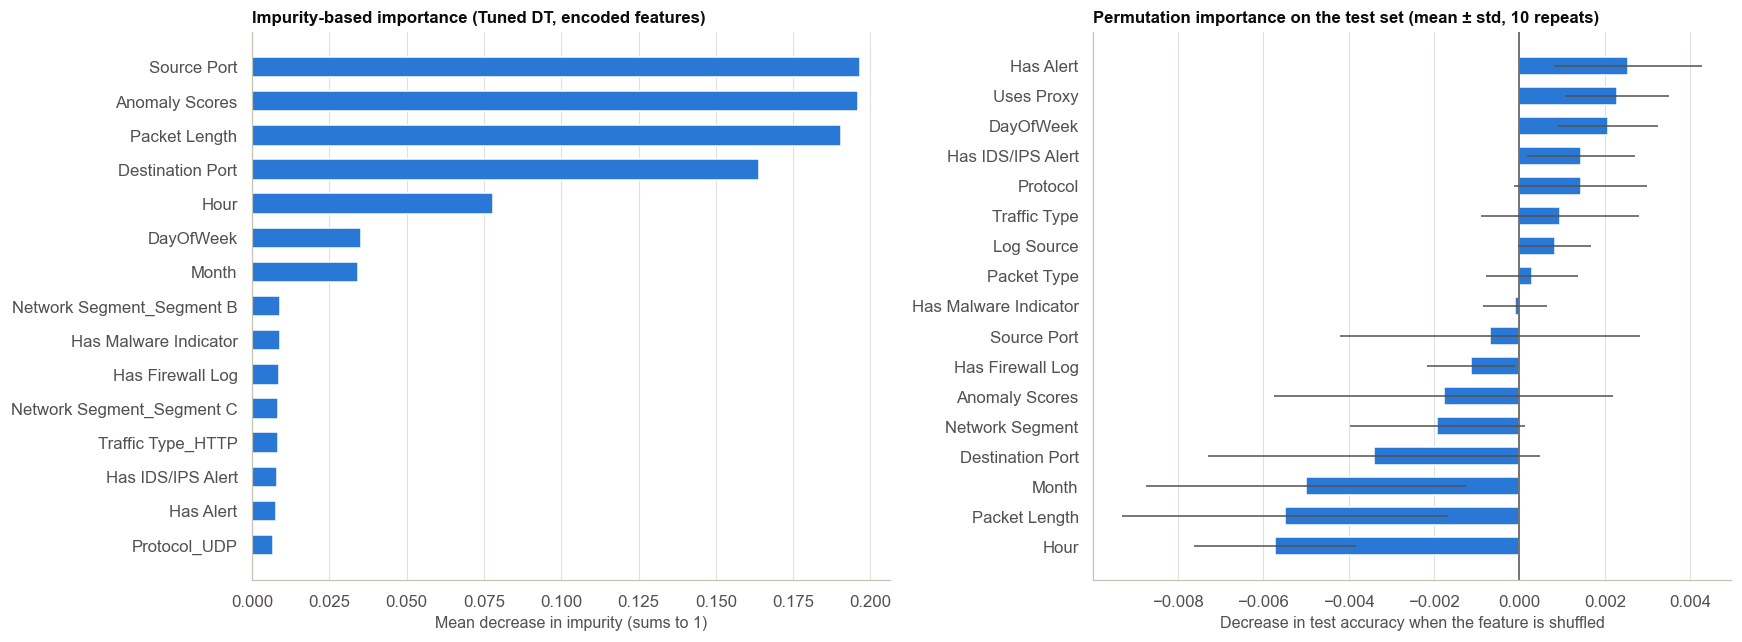

Top impurity-based importances:
Source Port                  0.1966
Anomaly Scores               0.1961
Packet Length                0.1906
Destination Port             0.1640
Hour                         0.0781
DayOfWeek                    0.0351
Month                        0.0343
Network Segment_Segment B    0.0090

Permutation importance (sorted):
                         mean     std
Has Alert              0.0025  0.0017
Uses Proxy             0.0023  0.0012
DayOfWeek              0.0021  0.0012
Has IDS/IPS Alert      0.0014  0.0013
Protocol               0.0014  0.0016
Traffic Type           0.0009  0.0019
Log Source             0.0008  0.0008
Packet Type            0.0003  0.0011
Has Malware Indicator -0.0001  0.0008
Source Port           -0.0007  0.0035
Has Firewall Log      -0.0011  0.0010
Anomaly Scores        -0.0018  0.0040
Network Segment       -0.0019  0.0021
Destination Port      -0.0034  0.0039
Month                 -0.0050  0.0037
Packet Length         -0.0055  0.0038


In [22]:
mdi = pd.Series(tuned_tree.feature_importances_, index=feature_names).sort_values(ascending=False)
mdi_top = mdi[mdi > 0].head(15)[::-1]

perm = permutation_importance(tuned, X_test, y_test, scoring='accuracy', n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_df = (pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std}, index=X_test.columns)
           .sort_values('mean'))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(mdi_top.index, mdi_top.values, color=ACCENT, height=0.6)
axes[0].set_title('Impurity-based importance (Tuned DT, encoded features)', fontsize=11)
axes[0].set_xlabel('Mean decrease in impurity (sums to 1)')
axes[0].grid(axis='y', visible=False)

axes[1].barh(perm_df.index, perm_df['mean'], xerr=perm_df['std'], color=ACCENT, height=0.6,
             error_kw={'ecolor': INK_2, 'elinewidth': 1})
axes[1].axvline(0, color=INK_2, lw=1)
axes[1].set_title('Permutation importance on the test set (mean ± std, 10 repeats)', fontsize=11)
axes[1].set_xlabel('Decrease in test accuracy when the feature is shuffled')
axes[1].grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('Top impurity-based importances:')
print(mdi.head(8).round(4).to_string())
print('\nPermutation importance (sorted):')
print(perm_df.sort_values('mean', ascending=False).round(4).to_string())

**Insight.**
* **MDI** credits the continuous features most: `Source Port` 0.197, `Anomaly Scores` 0.196, `Packet Length` 0.191, `Destination Port` 0.164 and `Hour` 0.078. This is the known bias of impurity-based importance: features with many possible thresholds offer the most opportunities to fit noise.
* **Permutation importance on unseen test data** tells the true story. Every feature changes test accuracy by less than ±0.6 percentage points, and the values are of the same size as their standard deviations. Several of the top MDI features even have *negative* permutation importance (`Packet Length` −0.0055, `Hour` −0.0057), which means shuffling them slightly *improves* test accuracy. The splits on these features capture noise.
* Conclusion: **no feature carries real predictive information** about the attack type.

## 4. Model Evaluation

### 4.1 Evaluation metrics on the test set

* **Accuracy** is the share of correct predictions.
* **Precision / Recall / F1** are computed per class and then averaged. *Macro* is the unweighted mean over classes. *Weighted* weights each class by its support.
* The 95% confidence interval of accuracy uses the normal approximation: $acc \pm 1.96\sqrt{acc(1-acc)/n}$.

In [23]:
models = {'Random guess (Dummy)': dummy, 'Baseline DT': baseline, 'Tuned DT': tuned}
predictions = {name: m.predict(X_test) for name, m in models.items()}
n_test = len(y_test)


def evaluate(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    half_width = 1.96 * math.sqrt(acc * (1 - acc) / len(y_true))
    return {
        'Accuracy': acc,
        'Acc 95% CI': f'[{acc - half_width:.4f}, {acc + half_width:.4f}]',
        'Precision (macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'F1 (macro)': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Precision (weighted)': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall (weighted)': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1 (weighted)': f1_score(y_true, y_pred, average='weighted', zero_division=0),
    }


results = pd.DataFrame({name: evaluate(y_test, pred) for name, pred in predictions.items()}).T
results['Train accuracy'] = [accuracy_score(y_train, m.predict(X_train)) for m in models.values()]
results['Overfitting gap (train - test acc)'] = results['Train accuracy'] - results['Accuracy']
num_cols = [c for c in results.columns if c != 'Acc 95% CI']
results[num_cols] = results[num_cols].astype(float).round(4)
results

,Accuracy,Acc 95% CI,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),Train accuracy,Overfitting gap (train - test acc)
Random guess (Dummy),0.3390,"[0.3286, 0.3494]",0.3390,0.3390,0.3390,0.3391,0.3390,0.3390,0.3325,-0.0065
Baseline DT,0.3324,"[0.3221, 0.3427]",0.3324,0.3324,0.3324,0.3324,0.3324,0.3323,1.0000,0.6676
Tuned DT,0.3299,"[0.3196, 0.3402]",0.3297,0.3298,0.3295,0.3297,0.3299,0.3295,0.5527,0.2228


### 4.2 Classification reports

In [24]:
for name in ['Baseline DT', 'Tuned DT']:
    print(f'===================== {name} =====================')
    print(classification_report(y_test, predictions[name], labels=CLASS_ORDER, digits=4, zero_division=0))

===================== Baseline DT =====================
              precision    recall  f1-score   support

        DDoS     0.3304    0.3220    0.3262      2686
   Intrusion     0.3396    0.3426    0.3411      2653
     Malware     0.3272    0.3326    0.3299      2661

    accuracy                         0.3324      8000
   macro avg     0.3324    0.3324    0.3324      8000
weighted avg     0.3324    0.3324    0.3323      8000

===================== Tuned DT =====================


              precision    recall  f1-score   support

        DDoS     0.3319    0.3544    0.3428      2686
   Intrusion     0.3327    0.3332    0.3330      2653
     Malware     0.3244    0.3018    0.3127      2661

    accuracy                         0.3299      8000
   macro avg     0.3297    0.3298    0.3295      8000
weighted avg     0.3297    0.3299    0.3295      8000



**Insight.** Per-class precision, recall and F1 all lie between 0.30 and 0.36 for both trees, around the 0.33 expected from random guessing. The tuned tree predicts *DDoS* slightly more often (recall 0.354) at the expense of *Malware* (recall 0.302). This small shift is not a learned pattern.

### 4.3 Confusion matrices

Each cell shows the number of test records and the percentage of the **true** class (row-normalised). A perfect model would show 100% on the diagonal.

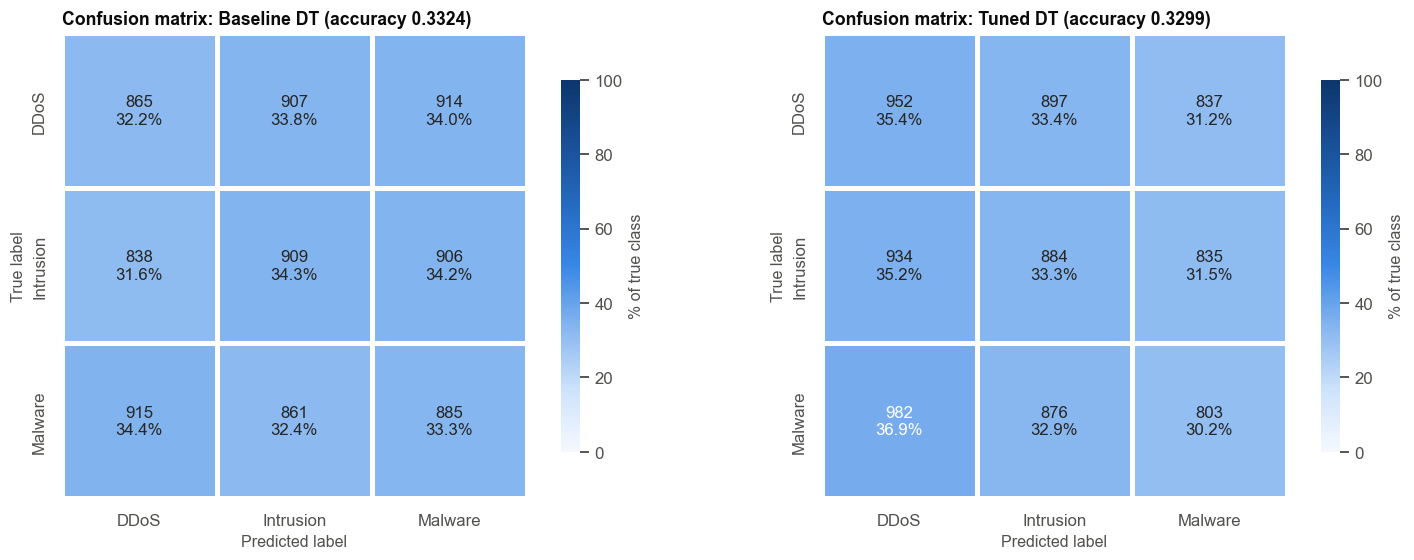

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, name in zip(axes, ['Baseline DT', 'Tuned DT']):
    cm = confusion_matrix(y_test, predictions[name], labels=CLASS_ORDER)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f'{cm[i, j]:,}\n{cm_pct[i, j]:.1f}%' for j in range(3)] for i in range(3)])
    sns.heatmap(cm_pct, annot=annot, fmt='', cmap=SEQ_CMAP, vmin=0, vmax=100, square=True,
                xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, linewidths=2, linecolor='white',
                cbar_kws={'label': '% of true class', 'shrink': 0.8}, annot_kws={'size': 11}, ax=ax)
    ax.set_title(f'Confusion matrix: {name} (accuracy {accuracy_score(y_test, predictions[name]):.4f})',
                 fontsize=11.5)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    ax.grid(False)
plt.tight_layout()
plt.show()

### 4.4 Model comparison chart

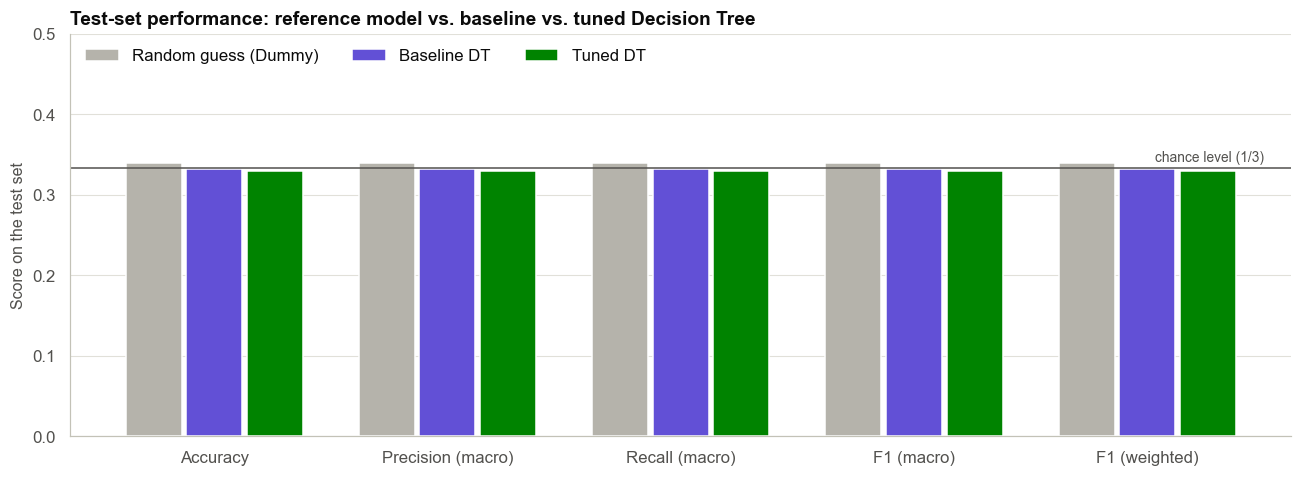

In [26]:
metric_cols = ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)', 'F1 (weighted)']
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(metric_cols))
w = 0.26
for k, name in enumerate(models):
    ax.bar(x + (k - 1) * w, results.loc[name, metric_cols].astype(float), width=w - 0.02,
           color=MODEL_COLORS[name], label=name)
ax.axhline(1 / 3, color=INK_2, lw=1)
ax.text(len(metric_cols) - 0.5, 1 / 3 + 0.008, 'chance level (1/3)', color=INK_2, fontsize=9, ha='right')
ax.set_xticks(x, metric_cols)
ax.set_ylim(0, 0.5)
ax.set_ylabel('Score on the test set')
ax.set_title('Test-set performance: reference model vs. baseline vs. tuned Decision Tree')
ax.legend(ncol=3, loc='upper left')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

### 4.5 Overfitting analysis: training vs. validation performance across tree depths

`validation_curve` re-trains the pipeline for several values of `max_depth` with 5-fold CV. The other hyperparameters are left at their defaults (no leaf-size limit), so the effect of depth alone is visible.

Validation curve computed in 16.7 s


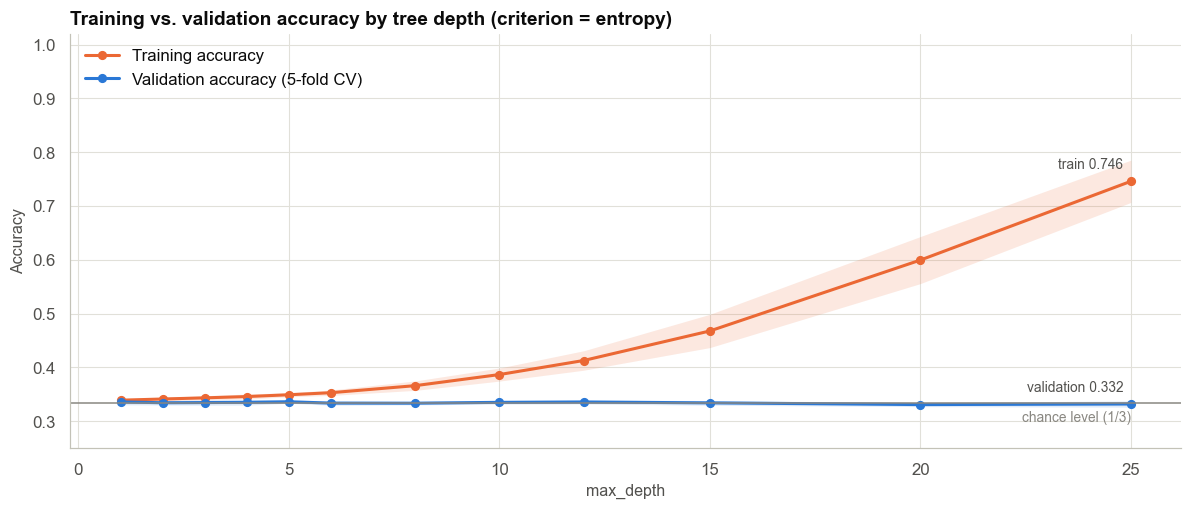

,max_depth,train_mean,train_std,val_mean,val_std,gap
0,1,0.3390,0.0029,0.3358,0.0053,0.0032
1,2,0.3412,0.0031,0.3343,0.0041,0.0069
2,3,0.3434,0.0039,0.3346,0.0049,0.0088
3,4,0.3458,0.0047,0.3350,0.0051,0.0107
4,5,0.3491,0.0037,0.3362,0.0029,0.0130
5,6,0.3530,0.0051,0.3336,0.0038,0.0194
6,8,0.3660,0.0088,0.3334,0.0031,0.0326
7,10,0.3867,0.0122,0.3350,0.0033,0.0516
8,12,0.4128,0.0181,0.3357,0.0036,0.0771
9,15,0.4677,0.0309,0.3341,0.0043,0.1336


In [27]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25]
t0 = time.perf_counter()
train_scores, val_scores = validation_curve(
    make_tree_pipeline(criterion=best['tree__criterion']), X_train, y_train,
    param_name='tree__max_depth', param_range=depths, cv=cv, scoring='accuracy', n_jobs=-1)
print(f'Validation curve computed in {time.perf_counter() - t0:.1f} s')

curve = pd.DataFrame({'max_depth': depths,
                      'train_mean': train_scores.mean(axis=1), 'train_std': train_scores.std(axis=1),
                      'val_mean': val_scores.mean(axis=1), 'val_std': val_scores.std(axis=1)})
curve['gap'] = curve['train_mean'] - curve['val_mean']

fig, ax = plt.subplots(figsize=(11, 4.8))
for col, label, color in [('train', 'Training accuracy', '#eb6834'), ('val', 'Validation accuracy (5-fold CV)', ACCENT)]:
    ax.plot(curve['max_depth'], curve[f'{col}_mean'], marker='o', ms=5, lw=2, color=color, label=label)
    ax.fill_between(curve['max_depth'], curve[f'{col}_mean'] - curve[f'{col}_std'],
                    curve[f'{col}_mean'] + curve[f'{col}_std'], color=color, alpha=0.15, lw=0)
ax.axhline(1 / 3, color=MUTED, lw=1)
ax.text(depths[-1], 1 / 3 - 0.035, 'chance level (1/3)', color=MUTED, fontsize=9, ha='right')
ax.annotate(f"train {curve['train_mean'].iloc[-1]:.3f}", (depths[-1], curve['train_mean'].iloc[-1]),
            xytext=(-5, 8), textcoords='offset points', ha='right', fontsize=9, color=INK_2)
ax.annotate(f"validation {curve['val_mean'].iloc[-1]:.3f}", (depths[-1], curve['val_mean'].iloc[-1]),
            xytext=(-5, 8), textcoords='offset points', ha='right', fontsize=9, color=INK_2)
ax.set_ylim(0.25, 1.02)
ax.set_xlabel('max_depth')
ax.set_ylabel('Accuracy')
ax.set_title(f"Training vs. validation accuracy by tree depth (criterion = {best['tree__criterion']})")
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()
curve.round(4)

**Insight.** This is the classic overfitting picture:
* **Training accuracy** rises steadily with depth, from 0.339 at depth 1 to 0.746 at depth 25 (the unlimited tree reaches 1.000).
* **Validation accuracy stays flat** between 0.331 and 0.336 at *every* depth, right on the chance line.
* The **gap** therefore grows from 0.003 (depth 1) to 0.414 (depth 25).

There is no "sweet spot" where validation accuracy peaks. Extra depth only adds memorisation, which is exactly what happens when the inputs contain no information about the target.

### 4.6 Is the model better than guessing?

The test accuracy is compared with the **no-information rate (NIR)**, which is the accuracy of always predicting the most frequent class. The comparison uses a one-sided z-test for a proportion, $H_0: acc \le NIR$.

In [28]:
nir = y_test.value_counts(normalize=True).max()
rows = []
for name, pred in predictions.items():
    acc = accuracy_score(y_test, pred)
    z = (acc - nir) / math.sqrt(nir * (1 - nir) / n_test)
    p_value = 0.5 * math.erfc(z / math.sqrt(2))
    rows.append({'model': name, 'test accuracy': round(acc, 4), 'NIR': round(nir, 4),
                 'difference (pp)': round((acc - nir) * 100, 2), 'z': round(z, 3),
                 'one-sided p-value': round(p_value, 4),
                 'significantly better than NIR (alpha = 0.05)?': 'yes' if p_value < 0.05 else 'no'})
pd.DataFrame(rows).set_index('model')

,test accuracy,NIR,difference (pp),z,one-sided p-value,significantly better than NIR (alpha = 0.05)?
model,,,,,,
Random guess (Dummy),0.3390,0.3358,0.33,0.616,0.2691,no
Baseline DT,0.3324,0.3358,-0.34,-0.639,0.7387,no
Tuned DT,0.3299,0.3358,-0.59,-1.113,0.8671,no


### 4.7 Most common misclassifications (Tuned DT)

In [29]:
cm = confusion_matrix(y_test, predictions['Tuned DT'], labels=CLASS_ORDER)
errors = []
for i, true_cls in enumerate(CLASS_ORDER):
    for j, pred_cls in enumerate(CLASS_ORDER):
        if i != j:
            errors.append({'true class': true_cls, 'predicted as': pred_cls, 'count': cm[i, j],
                           '% of true class': round(cm[i, j] / cm[i].sum() * 100, 2)})
errors = pd.DataFrame(errors).sort_values('count', ascending=False).reset_index(drop=True)
print(f'Total misclassified test records: {errors["count"].sum():,} of {n_test:,} '
      f'({errors["count"].sum() / n_test * 100:.2f}%)')
errors

Total misclassified test records: 5,361 of 8,000 (67.01%)


,true class,predicted as,count,% of true class
0,Malware,DDoS,982,36.90
1,Intrusion,DDoS,934,35.21
2,DDoS,Intrusion,897,33.40
3,Malware,Intrusion,876,32.92
4,DDoS,Malware,837,31.16
5,Intrusion,Malware,835,31.47


### 4.8 Discussion

**Results.**
* The tuned Decision Tree reached a test accuracy of **32.99%** (95% CI 31.96%–34.02%) and a macro F1 of **0.3295**.
* The baseline tree reached 33.24% accuracy and a macro F1 of 0.3324.
* The random-guess dummy scored 33.90%.
* None of the models is significantly better than the no-information rate of 33.58% (one-sided p-values 0.27–0.87). Their confidence intervals overlap almost completely.

**Common misclassifications.**
* The errors are spread almost uniformly over all six off-diagonal cells (31%–37% of each true class), with 5,361 of 8,000 test records (67.0%) misclassified.
* The largest single error is *Malware → DDoS* (982 records, 36.9% of Malware), mirroring the tuned tree's slight tendency to predict DDoS.
* No pair of attack types is systematically confused with each other. The tree behaves like a near-random labeller.

**Why does the model fail?**
* The failure is a property of the **data**, not of the algorithm or the tuning.
* The EDA showed that no feature is associated with `Attack Type`: the largest |r| is 0.011 and the largest Cramér's V is 0.022.
* The publicly available `cybersecurity_attacks.csv` is widely known to be a *synthetic* dataset in which labels appear to be assigned independently of the attributes.
* A Decision Tree is a high-variance learner, so on such data it simply memorises noise. Regularisation removes most of the memorisation but cannot create a signal that is not there.

**Limitations.**
1. The dataset appears synthetic, so the results say nothing about Decision Trees on real network traffic.
2. Only a compact hyperparameter grid (32 candidates) was searched. Given how flat the CV scores are, a larger grid would not change the conclusion.
3. Several columns (payload text, user-agent strings, geo-location) were dropped rather than engineered. They are random text in this dataset, but in real data they could carry signal.
4. A single random 80/20 split was used for the final test, although the 5-fold CV results agree with it.

**Possible improvements.**
1. **Use real, labelled network-intrusion data** such as CIC-IDS2017, UNSW-NB15 or NSL-KDD, where features (flow durations, byte counts, flags) are known to relate to attack classes.
2. **Richer feature engineering.** Extract browser/OS from `Device Information`, state from `Geo-location`, port categories (well-known vs. ephemeral) and TF-IDF features from `Payload Data`.
3. **Ensembles** (Random Forest, Gradient Boosting) reduce the variance of single trees. **Cost-complexity pruning** (`ccp_alpha`) is a more principled alternative to depth limits.
4. **Label-shuffling sanity check.** Retrain on shuffled labels. If the scores do not change, as expected here, it confirms that there is no signal.

## 5. Conclusion

* **Dataset.** There are 40,000 security events with 25 attributes and a perfectly balanced 3-class target (DDoS 33.6%, Intrusion 33.2%, Malware 33.3%). There are no duplicates. The ≈ 50% "missing" values in five indicator columns mean *indicator absent* rather than lost data.
* **Preprocessing.**
  * Six identifier / free-text columns were removed, as were three potentially leaking post-incident fields (`Attack Signature`, `Action Taken`, `Severity Level`) and the non-stationary `Year`.
  * Indicators became binary flags, and the timestamp became Month / DayOfWeek / Hour.
  * The data was split 80/20 with stratification. Imputation and one-hot encoding run inside a scikit-learn `Pipeline` to avoid leakage.
* **Models.**
  * The default tree overfits completely: depth 53, 11,178 leaves, 100% train accuracy but only 33.24% test accuracy.
  * 5-fold grid search selected `entropy`, `min_samples_split=50` and unlimited depth. This made the tree 86% smaller, but the test accuracy is 32.99% and the macro F1 is 0.3295.
* **Key finding.**
  * No model, tuned or not, beats chance. Test accuracy stays within ±0.6 percentage points of the 33.6% no-information rate, and the difference is not statistically significant.
  * EDA, permutation importance and the flat validation curve all agree: **the features of this dataset contain no information about the attack type**, so the Decision Tree can only memorise noise.
  * The pipeline itself is sound and reusable. Applied to a real intrusion-detection dataset, it would be expected to produce meaningful results.